# **Trabalho Prático 4 - Análise Numérica**

Trabalho realizado pelos alunos do Grupo 19 no âmbito da unidade curricular de Análise Numérica (M2018) — 2024/2025:

Bruno	Manuel	Teixeira	Araújo Nº 202207580\
João Pereira Lobato Nº 202306182\
Pedro	Sebastião	Loureiro Pinto	Bessa Nº 202307026

---

# **Objetivos do Trabalho**

Neste trabalho, temos como objetivo dar uso aos nossos conhecimentos acerca das diversas regras de integração numérica (retângulo, trapézio e simpson) simples e compostas, bem como sobre o cálculo dos respetivos erros de aproximação.

# **Métodos a utilizar**

Para desenvolver os programas a utilizar neste trabalho, recorremos à linguagem Python, uma vez que era aquela com a qual todos os elementos do grupo estavam mais familiarizados, tendo esta sido lecionada em cadeiras anteriores da Licenciatura em Matemática, para além de ser efetivamente simples e de fácil compreensão e leitura.


#Exercício 1

Para obter a tabela desejada, criamos um programa que calcula para cada k=1,..,10 a integral utilizando a regra composta do trapézio em $n=2^k$ intervalos.

Calculamos também o valor "exato" de I utilizando a regra do trapézio composta em $2^{14}$ intervalos, de forma a obtermos o valor mais preciso possível, obtendo assim os valores de cada $|I$ - $I_{n_k}|$.

Os valores obtidos pelo programa criado estão dispostos na Imagem 1 e a tabela 1 apresenta-os na forma desejada.

In [ ]:
import math
def f(x: float) -> float:
    return math.sin(math.sin(math.sin(math.sin(x))))  # Função f(x) dada

#Regra composta do trapézio
def trapezio_c(a: float, b: float, n: int) -> float:
    h=(b-a)/n    #"comprimento" de cada sub-intervalo
    x_i = a + h  #Valor inicial é x_1 = a+h
    soma=0
    for i in range(n-1):
        soma+=f(x_i)
        x_i+=h
    return (soma*h) + (h/2)*(f(a)+f(b))

i_exato=trapezio_c(0,2,2**14)  #valor "exato" de I

for k in range(1,11):  #cálculo para cada k=1,..,10 de I_nk e de |I - I_nk|
  ka=2**k
  print(trapezio_c(0,2,ka))
  print(abs(i_exato-trapezio_c(0,2,ka)))
  print('-----------')


0.9533749638740736
0.10146691196363844
-----------
1.0308378382617962
0.02400403757591585
-----------
1.0489039934457873
0.00593788239192472
-----------
1.053360809734676
0.0014810661030359995
-----------
1.054471816956037
0.0003700588816750727
-----------
1.0547493749971648
9.250084054723828e-05
-----------
1.0548187524860697
2.312335164234014e-05
-----------
1.0548360961083285
5.779729383537102e-06
-----------
1.0548404319670412
1.4438706708030935e-06
-----------
1.0548415159287914
3.599089206662853e-07
-----------


**Imagem 1:**

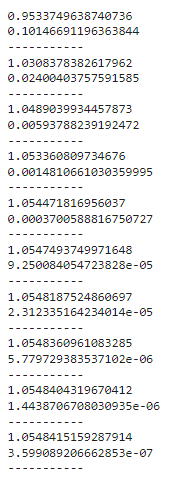

In [ ]:
from google.colab import data_table         #código usado para criar Tabela pedida
import pandas as pd

data = {
    'k' : ['1','2','3','4','5','6','7','8','9','10'],
    'n_k': ['2','4','8','16','32','64','128','256','512','1024'],
    'I_nk': ['0.9533749638740736', '1.0308378382617962', '1.0489039934457873', '1.053360809734676', '1.054471816956037', '1.0547493749971648', '1.0548187524860697', '1.0548360961083285','1.0548404319670412','1.0548415159287914'],
    '|I - I_nk| ': ['0.10146691196363844', '0.02400403757591585', '0.00593788239192472', '0.0014810661030359995', '0.0003700588816750727', '9.250084054723828e-05', '2.312335164234014e-05','5.779729383537102e-06','1.4438706708030935e-06','3.599089206662853e-07']

}
df = pd.DataFrame(data)
print('Tabela :')
data_table.DataTable(df, include_index=False, num_rows_per_page=10)

Tabela :


,k,n_k,I_nk,|I - I_nk|
0,1,2,0.9533749638740736,0.10146691196363844
1,2,4,1.0308378382617962,0.02400403757591585
2,3,8,1.0489039934457873,0.00593788239192472
3,4,16,1.053360809734676,0.0014810661030359995
4,5,32,1.054471816956037,0.0003700588816750727
5,6,64,1.0547493749971648,9.250084054723828e-05
6,7,128,1.0548187524860697,2.312335164234014e-05
7,8,256,1.0548360961083285,5.779729383537102e-06
8,9,512,1.0548404319670412,1.4438706708030935e-06
9,10,1024,1.0548415159287914,3.599089206662853e-07


**Tabela 1:**

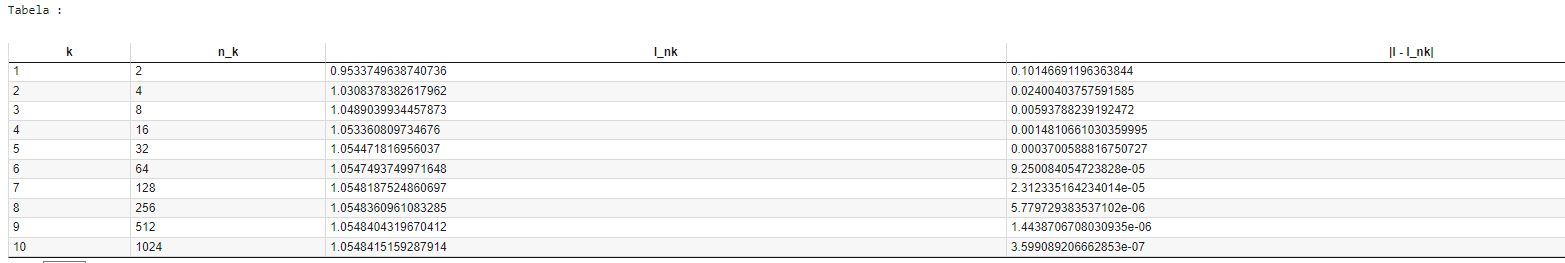

#Exercício 2

Para obter o majorante do erro é preciso calcular o máximo da segunda derivada no intervalo [0,2].

Em seguida, utilizamos a fórmula do erro da regra do trapézio composta:
$E=-\frac{h^2}{12}(b-a)f''(x)$;a<x<b.

Logo temos E ≤ $\frac{h^2}{12}(b-a)max_{a<x<b}|f''(x)|$

In [ ]:
import math
def f(x: float) -> float:
    return math.sin(math.sin(math.sin(math.sin(x))))  # Função f(x) dada


    #Fórmula para calcular segunda derivada
def segunda_derivada_numerica(f,x,h=1e-5):
    return (f(x+h)-2*f(x)+f(x-h))/(h*h)

    # Intervalo de integração
a = 0.0
b = 2.0

# 2) Calcular um majorante do erro para k=2 nk=4
n = 4

    # Calcular máximo da segunda derivada
N_pontos = 10000
xs = [a + i*(b-a)/N_pontos for i in range(N_pontos+1)]  #dividir o intervalo [a, b] por 10000 sub-intrevalos
max_f2 = 0.0
for xx in xs:
    f2 = abs(segunda_derivada_numerica(f, xx))
    if f2 > max_f2:          #Condição para determinar máximo no intervalo desejado
        max_f2 = f2

    #Fórmula para calcular majorante do erro
erro_majorante = ((b - a)**3 / (12.0 * n**2)) * max_f2

#Apresentação dos resultados
print("\nMajorante de erro para n_k=4:")
print(f"max|f''(x)| ≈ {max_f2:.5f}")
print(f"Erro <= {erro_majorante:.8e}")



Majorante de erro para n_k=4:
max|f''(x)| ≈ 1.08855
Erro <= 4.53562188e-02


Assim, quando $n_k$=4, temos que $I_{n_k}=1,031± 4.54 × 10^{-2}$

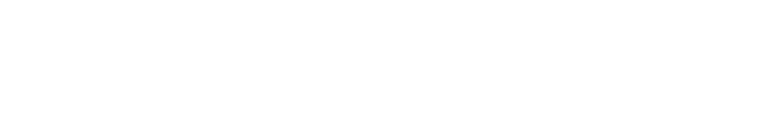